# Mapping Scheduled Public Transport Provision in the West Midlands

This notebook uses GTFS timetable data to examine spatial variation in scheduled public transport provision, focusing on service frequency, route diversity and the identification of key transport hubs.

The analysis uses a GTFS snapshot archived on 2 November 2026 and examines scheduled services operating on Tuesday 3 November 2026.

**What is GTFS?**

GTFS stands for General Transit Feed Specification. It's the standard format that public transport operators use to share their timetable and route data. A GTFS feed is a zip file containing a set of CSV files that together describe the entire network

| File | What it contains |
|---|---|
| stops.txt | Every stop/station — name, lat/lon |
| routes.txt | Every route — name, type (bus/rail/tube) |
| trips.txt | Every individual journey on every route |
| stop_times.txt | Every stop on every trip with arrival/departure times |
| calendar.txt | Which days each service runs |

In [1]:
from pathlib import Path
import hashlib
import zipfile
import shutil
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import os
import requests
import folium
import numpy as np
import pyproj
from datetime import datetime
from matplotlib.lines import Line2D
from html import escape
from shapely.geometry import box

In [2]:
# Specify file path for outputs
OUTPUT_DIR = Path.cwd() / "Outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# User-selected analysis date
ANALYSIS_DATE = "2026-11-03"  # Change this date (YYYY-MM-DD)

analysis_date = pd.Timestamp(ANALYSIS_DATE)
weekday = analysis_date.day_name().lower()

print(f"Selected analysis date: {analysis_date:%A %d %B %Y}")
weekday

Selected analysis date: Tuesday 03 November 2026


'tuesday'

##### Service calendar and analysis date

The analysis examines scheduled public transport services for a user-selected date, using an archived GTFS dataset.

Regular services are identified from `calendar.txt` according to the selected weekday, with additions and removals applied from `calendar_dates.txt`.

The resulting active service IDs and scheduled trip counts are reported below.

The results represent scheduled service provision rather than observed vehicle movements or service reliability.

##### Dataset version and reproducibility

This analysis uses a fixed GTFS timetable snapshot downloaded from the Department for Transport's Bus Open Data Service on 2 November 2026.

The notebook expects the original archive, named `gtfs_wm_20261102.zip`, to be located in the same directory as the notebook. A SHA-256 checksum verifies that the correct dataset version is being used.

The original archive is not distributed with this repository due to its size. The [BODS download page](https://data.bus-data.dft.gov.uk/timetable/download/gtfs-file/west_midlands/) provides updated GTFS data, which may not match the archived snapshot.

Exact reproduction of the published results requires the original archive. Using a newer dataset would require updating the dataset configuration and validation, rerunning the analysis and reviewing the resulting findings.

In [4]:
# Load the fixed West Midlands GTFS snapshot (archived locally on 2 November 2026)
GTFS_ARCHIVE = Path("gtfs_wm_20261102.zip")
GTFS_FOLDER = Path("gtfs_wm_20261102")

# Verify the dataset version using its SHA-256 checksum
EXPECTED_SHA256 = (
    "56e2f73ee49f77023c49f35f59d9e51"
    "a264f5e3d2dfb275a3a80151806a8d27e"
)

# Check that the required archive exists
if not GTFS_ARCHIVE.is_file():
    raise FileNotFoundError(
        f"Missing dataset: {GTFS_ARCHIVE}\n"
        "The original GTFS snapshot is required"
    )

# Verify that the archive has not changed
with GTFS_ARCHIVE.open("rb") as f:
    actual_sha256 = hashlib.file_digest(
        f, "sha256"
    ).hexdigest()

if actual_sha256 != EXPECTED_SHA256:
    raise ValueError(
        "GTFS archive checksum mismatch. "
        "The dataset is not the expected version"
    )

print("GTFS archive verified successfully")

GTFS archive verified successfully


In [5]:
# Extract the verified dataset into its own folder
GTFS_FOLDER.mkdir(exist_ok=True)

with zipfile.ZipFile(GTFS_ARCHIVE) as z:
    z.extractall(GTFS_FOLDER)

print("Extracted verified GTFS snapshot.")
print("Files available:")

for file in sorted(GTFS_FOLDER.iterdir()):
    if file.is_file():
        print(f"  {file.name}")

Extracted verified GTFS snapshot.
Files available:
  agency.txt
  calendar.txt
  calendar_dates.txt
  feed_info.txt
  routes.txt
  shapes.txt
  stop_times.txt
  stops.txt
  trips.txt


In [6]:
# Load and explore stops
stops = pd.read_csv(GTFS_FOLDER / "stops.txt")

print(f"Number of stops: {len(stops):,}")
print(f"Columns: {', '.join(stops.columns)}")

display(
    stops[
        ["stop_id", "stop_name", "stop_lat", "stop_lon"]
    ].head(5).style.hide(axis="index")
)

Number of stops: 30,507
Columns: stop_id, stop_code, stop_name, stop_lat, stop_lon, wheelchair_boarding, location_type, parent_station, platform_code


stop_id,stop_name,stop_lat,stop_lon
5140WDB22661,Cocoa Rooms,52.969105,-2.934764
3800C910202,Ninian Park,52.601250,-1.676446
43000785301,Short Street,52.600100,-2.039330
43000908102,Best Street,52.477780,-2.065030
43000686302,Forge Road,52.568910,-2.044450


Stops mapped: 30,507
Coordinate reference system: EPSG:27700


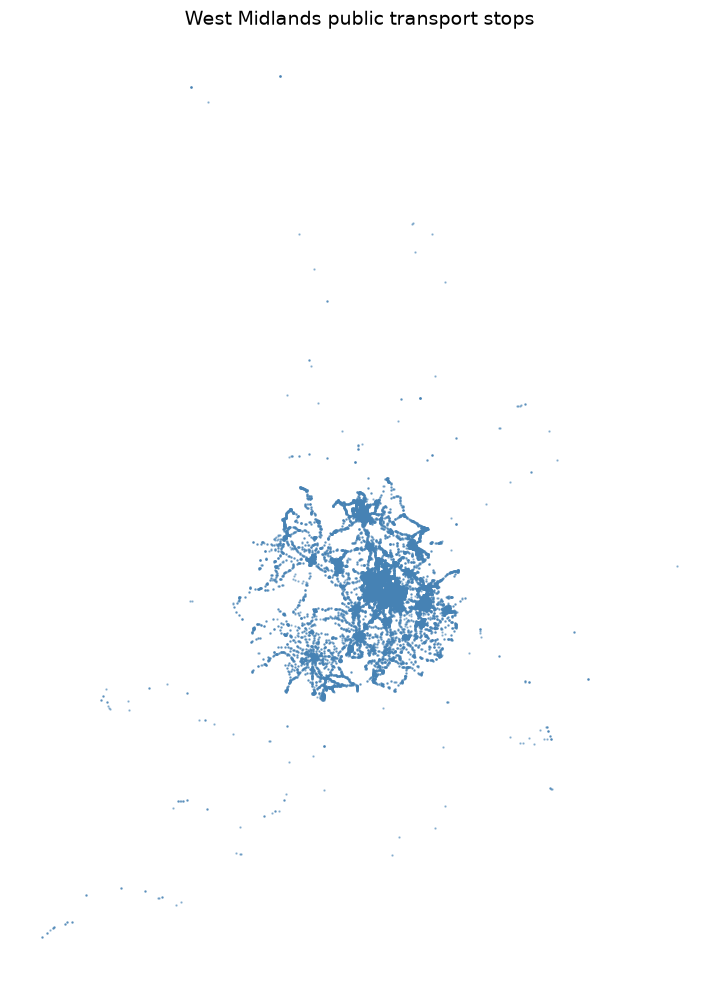

In [7]:
# Load stops as a GeoDataFrame and plot the network

# Convert stops to GeoDataFrame
gdf_stops = gpd.GeoDataFrame(
    stops,
    geometry=gpd.points_from_xy(stops['stop_lon'], stops['stop_lat']),
    crs='EPSG:4326'
).to_crs('EPSG:27700')
print(f"Stops mapped: {len(gdf_stops):,}")
print(f"Coordinate reference system: {gdf_stops.crs}")

# Plot stops GeoDataFrame
fig, ax = plt.subplots(figsize=(12, 10), facecolor='white')
gdf_stops.plot(ax=ax, color='steelblue', markersize=0.5, alpha=0.5)
ax.set_title('West Midlands public transport stops', fontsize=14)
ax.axis('off')
plt.tight_layout()
plt.savefig(OUTPUT_DIR /'wm_bus_frequency.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

#### Geographic distribution of public transport stops

The GTFS stop locations are converted into a GeoDataFrame and projected from WGS84 (`EPSG:4326`) to British National Grid (`EPSG:27700`) for spatial analysis.

The map provides an overview of the geographical coverage of stops included in the feed. It shows stop locations rather than service frequency or accessibility.

The dataset extends beyond the West Midlands metropolitan area, so the mapped network should not be interpreted as representing only the West Midlands county.

In [8]:
# Load routes and explore the network
routes = pd.read_csv(GTFS_FOLDER / "routes.txt")

print(f"Total route records: {len(routes):,}")

# Summarise routes by transport mode
route_type_names = {
    0: "Tram",
    3: "Bus",
    200: "Coach"
}

route_summary = (
    routes["route_type"]
    .value_counts()
    .rename_axis("route_type")
    .reset_index(name="number_of_routes")
)

route_summary["transport_mode"] = (
    route_summary["route_type"]
    .map(route_type_names)
    .fillna("Other")
)

display(
    route_summary[
        ["route_type", "transport_mode", "number_of_routes"]
    ].style.hide(axis="index")
)


Total routes: 1,166


route_type,transport_mode,number_of_routes
3,Bus,1088
200,Coach,76
0,Tram,2


#### Transport modes

The GTFS feed contains 1,166 routes, classified using standard and extended GTFS route-type codes:

Bus routes account for the majority of the network. Subsequent analyses distinguish bus-only services from the wider network where appropriate.

Route classifications are taken from the GTFS feed and may not capture every operational distinction between services.

In [9]:
# Load trips and count services per stop
trips = pd.read_csv(GTFS_FOLDER / "trips.txt")
stop_times = pd.read_csv(GTFS_FOLDER / "stop_times.txt", 
                          usecols=['trip_id', 'stop_id', 'arrival_time', 'departure_time', 'stop_sequence'])

# Summarise the size of the full GTFS feed
dataset_summary = pd.DataFrame({
    "Dataset": ["Trips", "Stop-time records"],
    "Records": [len(trips), len(stop_times)]
})

display(
    dataset_summary.style
    .format({"Records": "{:,.0f}"})
    .hide(axis="index")
)

Dataset,Records
Trips,"168,471"
Stop-time records,"6,576,819"


#### GTFS trips and stop times

The GTFS dataset contains 168,471 trips and 6,576,819 stop-time records. These represent scheduled services in the feed, not services operating on a single day.

Each row in `stop_times.txt` represents a scheduled stop event within a trip:

- `trip_id` identifies the scheduled trip.
- `stop_id` identifies the stop.
- `stop_sequence` gives the order of stops along the trip.
- `arrival_time` and `departure_time` record the scheduled times.

To analyse services operating on a particular weekday, the trips must first be filtered using the GTFS service calendar and any calendar exceptions.

In [10]:
# Explore how many trips serve each stop
trips_per_stop = stop_times.groupby('stop_id')['trip_id'].nunique().reset_index()
trips_per_stop.columns = ['stop_id', 'trip_count']

print(f"Stops with at least one service: {len(trips_per_stop)}")
print(f"\nTop 10 busiest stops:")
print(trips_per_stop.sort_values('trip_count', ascending=False).head(10))

print(f"\nBottom 10 least served stops:")
print(trips_per_stop.sort_values('trip_count', ascending=True).head(10))


Stops with at least one service: 30408

Top 10 busiest stops:
           stop_id  trip_count
2190   2000G000110       13103
2500   2000G006698        8947
2251   2000G000716        6288
4684   2000G590009        6222
3506   2000G202504        6196
3984   2000G500909        5856
3537   2000G241205        5583
2691   2000G016301        5479
20270  43000211301        4394
2422   2000G005381        4234

Bottom 10 least served stops:
            stop_id  trip_count
15728   4200F053900           1
15724   4200F053600           1
5707    2090A150200           1
3826    2000G323429           1
3825    2000G323428           1
4628    2000G52879B           1
30196  5610WDB22992           1
3594    2000G323067           1
30102  5610PWX18528           1
30101  5610PWX18526           1


#### Exploring scheduled trips per stop

As an initial exploration, the number of distinct trips associated with each stop is calculated across the full GTFS feed.

These counts provide an overview of the timetable data but are not directly comparable measures of daily service provision, because trips may operate on different dates.

Subsequent analysis therefore uses a specific weekday and applies the GTFS service calendar to identify trips scheduled to operate on that date.

In [11]:
# Join trip counts to spatial data and plot

# Merge trip counts with stop locations
gdf_stops_freq = gdf_stops.merge(trips_per_stop, on='stop_id', how='left')
gdf_stops_freq['trip_count'] = gdf_stops_freq['trip_count'].fillna(0)

# Summarise distinct trips per stop across the full feed
trip_summary = pd.DataFrame({
    "Metric": [
        "Stops with recorded trips",
        "Maximum trips at a stop",
        "Mean trips per stop"
    ],
    "Value": [
        len(trips_per_stop),
        trips_per_stop["trip_count"].max(),
        trips_per_stop["trip_count"].mean()
    ]
})

display(
    trip_summary.style
    .format({"Value": "{:,.0f}"})
    .hide(axis="index")
)

Metric,Value
Stops with recorded trips,"30,408"
Maximum trips at a stop,"13,103"
Mean trips per stop,216


In [12]:
# Look at the calendar
calendar = pd.read_csv(GTFS_FOLDER / "calendar.txt")
calendar_dates = pd.read_csv(GTFS_FOLDER / "calendar_dates.txt")


# Summarise the GTFS service calendar
calendar_summary = pd.DataFrame({
    "Metric": [
        "Regular service patterns",
        "Calendar exception records",
        "Earliest regular service start",
        "Latest regular service end"
    ],
    "Value": [
        f"{len(calendar):,}",
        f"{len(calendar_dates):,}",
        pd.to_datetime(
            str(calendar["start_date"].min()),
            format="%Y%m%d"
        ).strftime("%d %B %Y"),
        pd.to_datetime(
            str(calendar["end_date"].max()),
            format="%Y%m%d"
        ).strftime("%d %B %Y")
    ]
})

display(calendar_summary.style.hide(axis="index"))


Metric,Value
Regular service patterns,277
Calendar exception records,"27,499"
Earliest regular service start,22 October 2026
Latest regular service end,13 September 2027


#### Understanding the GTFS service calendar

The GTFS feed contains regular service patterns (calendar.txt) and date-specific exceptions (calendar_dates.txt).

In calendar_dates.txt:

* exception_type = 1: A service is added on the specified date.

* exception_type = 2: A service is removed on the specified date.

Some service patterns operate for only a short period, so the full feed (22 October 2026 to 13 September 2027) cannot be used to represent a single day's timetable. The analysis therefore applies both calendar files to identify services scheduled to operate on Tuesday 3 November 2026.

In [13]:
# Identify services scheduled for the analysis date
target_date = int(analysis_date.strftime("%Y%m%d"))
print("Analysis date:", analysis_date.strftime("%A %d %B %Y"))

# Regular services operating on the selected weekday
regular = calendar[
    (calendar[weekday] == 1) &
    (calendar["start_date"] <= target_date) &
    (calendar["end_date"] >= target_date)
]["service_id"]

# Service additions and removals for the selected date
added = calendar_dates[
    (calendar_dates["date"] == target_date) &
    (calendar_dates["exception_type"] == 1)
]["service_id"]

removed = calendar_dates[
    (calendar_dates["date"] == target_date) &
    (calendar_dates["exception_type"] == 2)
]["service_id"]

# Apply calendar exceptions
active_services = (set(regular) | set(added)) - set(removed)
trips_day = trips[trips["service_id"].isin(active_services)].copy()

# Summarise services operating on the analysis date
service_summary = pd.DataFrame({
    "Metric": [
        "Analysis date",
        "Active service patterns",
        "Scheduled trips",
        "Trips in full GTFS feed"
    ],
    "Value": [
        analysis_date.strftime("%A %d %B %Y"),
        f"{len(active_services):,}",
        f"{len(trips_day):,}",
        f"{len(trips):,}"
    ]
})

display(service_summary.style.hide(axis="index"))

Analysis date: Tuesday 03 November 2026


Metric,Value
Analysis date,Tuesday 03 November 2026
Active service patterns,187
Scheduled trips,"36,410"
Trips in full GTFS feed,"168,471"


#### Service calendar and analysis date

The analysis examines scheduled public transport services on **Tuesday 3 November 2026**, using the GTFS dataset archived on 2 November 2026.

Regular weekday services were identified from `calendar.txt`, with additions and removals applied from `calendar_dates.txt`.

This produced **187 active service IDs and 36,410 scheduled trips**.

The results represent scheduled service provision rather than observed vehicle movements or service reliability.

In [14]:
# Explore scheduled trips per stop on the selected date

# Keep only stop times for trips running on the selected date
st_day = stop_times[
    stop_times["trip_id"].isin(trips_day["trip_id"])
].copy()

# Count distinct scheduled trips per stop
trips_per_stop_day = (
    st_day.groupby("stop_id")["trip_id"]
    .nunique()
    .reset_index(name="daily_trips")
)

# Add stop names and compare with the full-feed count
compare = (
    stops[["stop_id", "stop_name"]]
    .merge(trips_per_stop_day, on="stop_id", how="left")
    .merge(trips_per_stop, on="stop_id", how="left")
)

compare[["daily_trips", "trip_count"]] = (
    compare[["daily_trips", "trip_count"]].fillna(0)
)

# Summarise daily service activity
daily_summary = pd.DataFrame({
    "Metric": [
        "Stops with at least one scheduled trip",
        "Total stops in the feed",
        "Maximum scheduled trips at a stop",
        "Mean scheduled trips per served stop"
    ],
    "Value": [
        (compare["daily_trips"] > 0).sum(),
        len(compare),
        compare["daily_trips"].max(),
        trips_per_stop_day["daily_trips"].mean()
    ]
})

display(
    daily_summary.style
    .format({"Value": "{:,.0f}"})
    .hide(axis="index")
)

# Display the 15 stops with the most scheduled trips
top_stops = (
    compare.sort_values("daily_trips", ascending=False)
    [["stop_name", "daily_trips"]]
    .head(15)
    .rename(columns={
        "stop_name": "Stop",
        "daily_trips": "Scheduled trips"
    })
)

display(
    top_stops.style
    .format({"Scheduled trips": "{:,.0f}"})
    .hide(axis="index")
)

Metric,Value
Stops with at least one scheduled trip,"29,684"
Total stops in the feed,"30,507"
Maximum scheduled trips at a stop,"1,262"
Mean scheduled trips per served stop,46


Stop,Scheduled trips
Birmingham International Airport (Air-Rail link),"1,262"
Birmingham Intl Rail Station (Air-Rail Link),"1,262"
Worcester Bus Station,"1,074"
Birmingham Coach Station,943
Bus Mall,804
Adderley Street,802
Park Street,781
The Cross,744
Well Street,743
Newhall Street,694


#### Scheduled trips per stop on the analysis date

Stop-time records are filtered to services operating on the selected date. The number of distinct scheduled trips serving each stop is then calculated to identify where timetable activity is concentrated.

These counts cover the full operating day and do not distinguish between peak and off-peak provision. The subsequent analysis therefore examines scheduled daytime departures per hour.

In [15]:
# Define the time periods used throughout the analysis
TIME_PERIODS = {
    "am_peak": (7, 10),
    "interpeak": (10, 16),
    "pm_peak": (16, 19),
    "evening": (19, 24),
    "daytime": (7, 19)
}

def calculate_stop_frequency(stop_times_subset, stops):
    """Calculate average scheduled departures per hour by stop and period."""

    departures = stop_times_subset.dropna(
        subset=["departure_time"]
    ).copy()

    # GTFS times may exceed 24:00:00
    departures["hour"] = (
        departures["departure_time"]
        .str.split(":").str[0].astype(int)
    )

    frequency_tables = []

    for period, (start, end) in TIME_PERIODS.items():
        period_departures = departures[
            (departures["hour"] >= start) &
            (departures["hour"] < end)
        ]

        period_frequency = (
            period_departures.groupby("stop_id")
            .size()
            .div(end - start)
            .rename(f"{period}_per_hour")
        )

        frequency_tables.append(period_frequency)

    result = (
        pd.concat(frequency_tables, axis=1)
        .fillna(0)
        .reset_index()
        .rename(columns={
            "daytime_per_hour": "departures_per_hour"
        })
        .merge(
            stops[["stop_id", "stop_name"]],
            on="stop_id",
            how="left"
        )
    )

    result["frequency_band"] = pd.cut(
        result["departures_per_hour"],
        bins=[-0.001, 0, 0.5, 1, 2, 4, float("inf")],
        labels=[
            "No daytime service",
            "Very low (≤0.5/hr)",
            "Low (0.5–1/hr)",
            "Moderate (1–2/hr)",
            "High (2–4/hr)",
            "Very high (>4/hr)"
        ]
    )

    return result

freq = calculate_stop_frequency(st_day, stops)


def display_frequency_results(frequency_data, title):
    """Display frequency distribution and top 10 busiest stops."""

    print(f"\n{title}")
    print("Frequency distribution (07:00–19:00)")

    # Frequency band summary
    frequency_summary = (
        frequency_data["frequency_band"]
        .value_counts()
        .sort_index()
        .rename_axis("Frequency band")
        .reset_index(name="Number of stops")
    )

    display(
        frequency_summary.style
        .format({"Number of stops": "{:,.0f}"})
        .hide(axis="index")
    )

    print("Top 10 stops by average daytime departures per hour")

    # Top 10 stops, showing all time periods
    top_frequency = (
        frequency_data
        .sort_values("departures_per_hour", ascending=False)
        [[
            "stop_name",
            "am_peak_per_hour",
            "interpeak_per_hour",
            "pm_peak_per_hour",
            "evening_per_hour",
            "departures_per_hour"
        ]]
        .head(10)
        .rename(columns={
            "stop_name": "Stop",
            "am_peak_per_hour": "AM peak (07–10)",
            "interpeak_per_hour": "Interpeak (10–16)",
            "pm_peak_per_hour": "PM peak (16–19)",
            "evening_per_hour": "Evening (19–24)",
            "departures_per_hour": "Daytime average (07–19)"
        })
    )

    display(
        top_frequency.style
        .format({
            col: "{:.1f}"
            for col in top_frequency.columns
            if col != "Stop"
        })
        .hide(axis="index")
    )

freq = calculate_stop_frequency(st_day, stops)

display_frequency_results(
    freq,
    "All transport modes"
)


All transport modes
Frequency distribution (07:00–19:00)


Frequency band,Number of stops
No daytime service,110
Very low (≤0.5/hr),"5,299"
Low (0.5–1/hr),"6,051"
Moderate (1–2/hr),"5,874"
High (2–4/hr),"5,272"
Very high (>4/hr),"7,034"


Top 10 stops by average daytime departures per hour


Stop,AM peak (07–10),Interpeak (10–16),PM peak (16–19),Evening (19–24),Daytime average (07–19)
Worcester Bus Station,70.3,82.7,75.3,22.8,77.8
Birmingham Intl Rail Station (Air-Rail Link),60.0,60.0,60.0,60.0,60.0
Birmingham International Airport (Air-Rail link),60.0,60.0,60.0,60.0,60.0
Birmingham Coach Station,61.3,57.8,60.3,28.0,59.3
The Cross,46.7,56.3,53.7,16.0,53.2
Park Street,53.0,51.8,48.3,21.4,51.2
Adderley Street,52.0,49.3,52.3,23.2,50.8
Bus Mall,52.7,50.3,49.3,25.0,50.7
Well Street,48.7,45.8,46.7,26.8,46.8
Newhall Street,44.3,44.3,43.0,22.4,44.0


#### Daytime scheduled service frequency

Scheduled departures are analysed across four time periods on the selected analysis date:

- AM peak (07:00–10:00)
- Interpeak (10:00–16:00)
- PM peak (16:00–19:00)
- Evening (19:00–24:00)

Departure events are counted at each stop and divided by the duration of each period to calculate average scheduled departures per hour. An overall daytime average (07:00–19:00) is also calculated and used to classify stops into frequency bands, with a separate category for stops with no scheduled daytime departures.

The results illustrate differences in scheduled service provision throughout the day, particularly the reduction in evening services at major interchange locations. The Birmingham International Air-Rail Link is an exception, maintaining a consistent scheduled frequency across all four periods.

These figures describe scheduled provision rather than actual departures, waiting times or service reliability.

In [16]:
# Look at bus only services on selected-day

# Filter to bus services only
bus_route_ids = routes.loc[
    routes["route_type"].astype(str) == "3",
    "route_id"
]

# Filter to selected-day only
bus_trip_ids = trips_day.loc[
    trips_day["route_id"].isin(bus_route_ids),
    "trip_id"
]

# Filter stop times to bus services
bus_stop_times = st_day[
    st_day["trip_id"].isin(bus_trip_ids)
].copy()

# Calculate frequency by time period
bus_freq = calculate_stop_frequency(bus_stop_times, stops)

bus_freq["bus_departures_per_hour"] = (
    bus_freq["departures_per_hour"]
)

display_frequency_results(
    bus_freq,
    "Bus services only"
)


Bus services only
Frequency distribution (07:00–19:00)


Frequency band,Number of stops
No daytime service,93
Very low (≤0.5/hr),"5,185"
Low (0.5–1/hr),"6,024"
Moderate (1–2/hr),"5,855"
High (2–4/hr),"5,259"
Very high (>4/hr),"6,959"


Top 10 stops by average daytime departures per hour


Stop,AM peak (07–10),Interpeak (10–16),PM peak (16–19),Evening (19–24),Daytime average (07–19)
Worcester Bus Station,70.3,82.7,75.3,22.8,77.8
Birmingham Coach Station,61.3,57.8,60.3,28.0,59.3
The Cross,46.7,56.3,53.7,16.0,53.2
Park Street,53.0,51.8,48.3,21.4,51.2
Adderley Street,52.0,49.3,52.3,23.2,50.8
Bus Mall,52.7,50.3,49.3,25.0,50.7
Well Street,48.7,45.8,46.7,26.8,46.8
Newhall Street,44.3,44.3,43.0,22.4,44.0
Starley Gardens,41.3,43.3,44.3,22.4,43.1
Theatre Approach,44.0,43.3,40.7,21.0,42.8


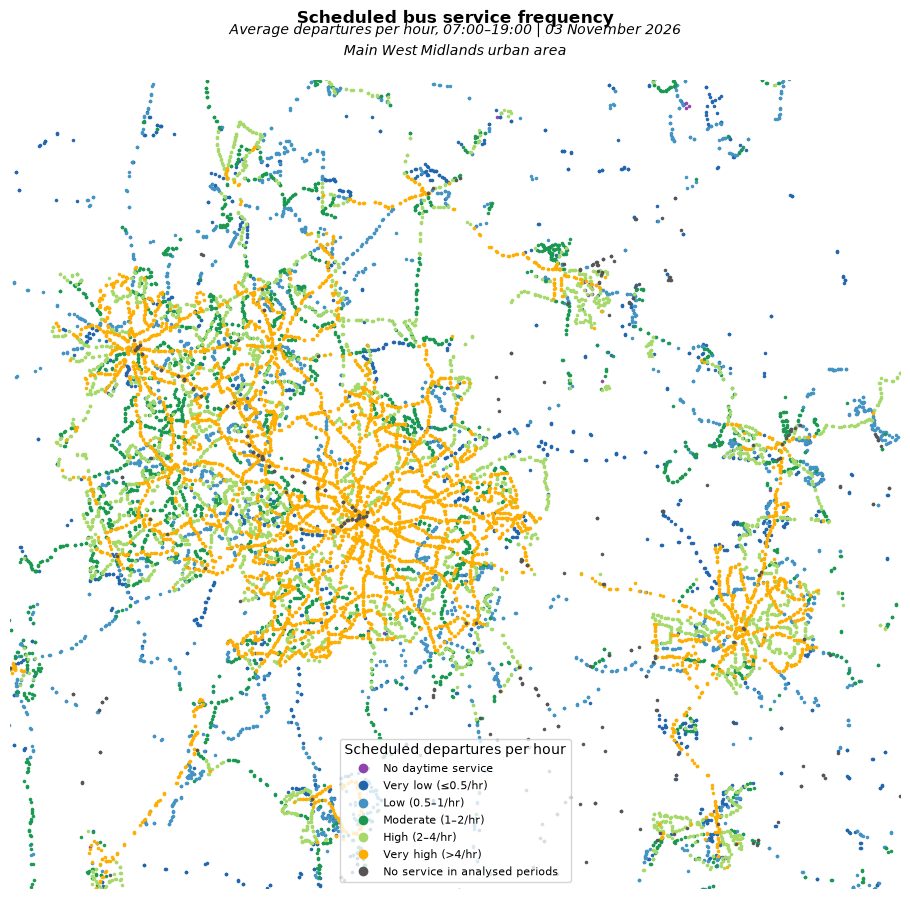

In [17]:
# Map average scheduled bus departures per hour, 07:00–19:00

from matplotlib.lines import Line2D

# Join bus frequency results to stop geometries
gdf_bus_freq = gdf_stops.merge(
    bus_freq[["stop_id", "departures_per_hour", "frequency_band"]],
    on="stop_id",
    how="left"
)

# Define colours for frequency bands
band_colours = {
    "No daytime service": "#8e44ad",          # Purple
    "Very low (≤0.5/hr)": "#2166ac",          # Dark blue
    "Low (0.5–1/hr)": "#4393c3",              # Light blue
    "Moderate (1–2/hr)": "#1a9850",           # Green
    "High (2–4/hr)": "#a6d96a",               # Light green
    "Very high (>4/hr)": "#fdae00",           # Yellow-orange
    "No service in analysed periods": "#555555"  # Dark grey
}

# Include stops with no departures between 07:00 and 24:00
gdf_bus_freq["frequency_band"] = (
    gdf_bus_freq["frequency_band"]
    .cat.add_categories(["No service in analysed periods"])
    .fillna("No service in analysed periods")
)


# Define a geographic focus around the main urban area
# Coordinates are longitude/latitude (EPSG:4326)
map_extent = (-2.25, -1.35, 52.25, 52.75)

fig, ax = plt.subplots(figsize=(11, 9))

# Draw lower-frequency stops first
for band, colour in band_colours.items():

    subset = gdf_bus_freq[
        gdf_bus_freq["frequency_band"] == band
    ]

    if not subset.empty:
        subset.plot(
            ax=ax,
            color=colour,
            markersize=2.5,
            alpha=0.95
        )

# Set extent, transforming it if needed
from shapely.geometry import box
import geopandas as gpd

extent_gdf = gpd.GeoSeries(
    [box(
        map_extent[0],
        map_extent[2],
        map_extent[1],
        map_extent[3]
    )],
    crs="EPSG:4326"
).to_crs(gdf_bus_freq.crs)

xmin, ymin, xmax, ymax = extent_gdf.total_bounds

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# Create legend for the mapped area
handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=colour,
        markeredgecolor="none",
        markersize=7,
        label=band
    )
    for band, colour in band_colours.items()
]

ax.legend(
    handles=handles,
    title="Scheduled departures per hour",
    loc="lower center",
    fontsize=8,
    frameon=True
)

# Main title — bold and larger
ax.text(
    0.5, 1.07,
    "Scheduled bus service frequency",
    transform=ax.transAxes,
    ha="center",
    fontsize=12,
    fontweight="bold"
)

# Subtitle — smaller and italic
ax.text(
    0.5, 1.025,
    f"Average departures per hour, 07:00–19:00 | {analysis_date:%d %B %Y}\n"
    "Main West Midlands urban area",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=10,
    fontstyle="italic",
    linespacing=1.4
)

ax.set_axis_off()

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR /"wm_bus_frequency.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

In [18]:
# Calculate bus route diversity at each stop
# Use scheduled bus departures between 07:00 and 19:00

bus_daytime = bus_stop_times.dropna(
    subset=["departure_time"]
).copy()

bus_daytime["hour"] = (
    bus_daytime["departure_time"]
    .str.split(":").str[0].astype(int)
)

bus_daytime = bus_daytime[
    bus_daytime["hour"].between(7, 18)
]

# Attach route IDs to scheduled bus stop events
bus_daytime = bus_daytime.merge(
    trips_day[["trip_id", "route_id"]],
    on="trip_id",
    how="left"
)

# Count distinct bus routes serving each stop
stop_profile = (
    bus_daytime.groupby("stop_id")
    .agg(n_routes=("route_id", "nunique"))
    .reset_index()
    .merge(
        stops[["stop_id", "stop_name"]],
        on="stop_id",
        how="left"
    )
    .merge(
        bus_freq[["stop_id", "departures_per_hour"]],
        on="stop_id",
        how="left"
    )
)

# Categorise stops by number of routes
stop_profile["route_band"] = pd.cut(
    stop_profile["n_routes"],
    bins=[0, 1, 3, 7, 15, float("inf")],
    labels=[
        "1 route",
        "2–3 routes",
        "4–7 routes",
        "8–15 routes",
        "16+ routes"
    ]
)

# Add bus route numbers to each stop
route_lookup = routes[
    ["route_id", "route_short_name"]
].drop_duplicates(subset="route_id")

stop_route_names = (
    bus_daytime[["stop_id", "route_id"]]
    .drop_duplicates()
    .merge(route_lookup, on="route_id", how="left")
    .groupby("stop_id")["route_short_name"]
    .agg(lambda x: ", ".join(
        sorted(x.dropna().astype(str).unique())
    ))
    .reset_index(name="route_numbers")
)

stop_profile = stop_profile.merge(
    stop_route_names,
    on="stop_id",
    how="left"
)

# Summary of route diversity
route_summary = (
    stop_profile["route_band"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of routes")
    .reset_index(name="Number of stops")
)

display(
    route_summary.style
    .format({"Number of stops": "{:,.0f}"})
    .hide(axis="index")
)


# Top 15 stops by bus route diversity
top_routes = (
    stop_profile.sort_values(
        ["n_routes", "departures_per_hour"],
        ascending=False
    )
    [[
        "stop_id",
        "stop_name",
        "n_routes",
        "route_numbers",
        "departures_per_hour"
    ]]
    .head(15)
    .rename(columns={
        "stop_id": "Stop ID",
        "stop_name": "Stop",
        "n_routes": "Bus routes",
        "route_numbers": "Routes served",
        "departures_per_hour": "Daytime departures/hr"
    })
)

display(
    top_routes.style
    .format({
        "Bus routes": "{:,.0f}",
        "Daytime departures/hr": "{:.1f}"
    })
    .hide(axis="index")
)


Number of routes,Number of stops
1 route,"13,913"
2–3 routes,"10,941"
4–7 routes,"3,909"
8–15 routes,466
16+ routes,53


Stop ID,Stop,Bus routes,Routes served,Daytime departures/hr
2000G000110,Worcester Bus Station,33,"144, 153, 22, 22A, 27, 28, 31, 310, 311, 313, 314, 315, 316, 31A, 32, 332, 333, 334, 34, 35, 36, 363, 365, 38, 417, 420, 420A, 43, 44, 51, X28, X38, X50",77.8
4200F067200,NatWest Bank,32,"1, 15, 19, 1A, 2, 212, 229, 26, 27, 28, 2A, 3, 3A, 4, 5, 50, 51, 51A, 6, 75, 75A, 76, 76A, 77, 77S, PR, X16, X18, X20, X21",18.5
3890D000100,bus station,31,"101, 103, 11, 11B, 11X, 16, 18, 2, 21, 218, 23, 24, 25, 32, 32A, 32X, 38, 39, 43, 5, 6, 61, 6A, 6C, 7, 7A, 8, 8A",39.5
4200F065200,McDonalds,25,"1, 15, 1A, 2, 212, 229, 26, 27, 28, 2A, 3, 3A, 4, 50, 51A, 6, 75A, 76, 76A, 76X, 77, 77E, X16, X18",9.6
43000006301,Code Building,24,"11, 12X, 13, 13A, 24A, 25, 25A, 3, 3S, 7, 74B, 74C, 7A, 7B, 8, 85, 85B, 85H, 85K, 85S, 8B, 9, 9B, X30",42.4
3890D034702,Quadrant Road,24,"16, 18, 2, 218, 24, 26, 32, 32A, 32X, 43, 5, 60, 61, 62, 7, 7A, 8, 8A, 9, 9A, 9B",21.2
43001053502,Starley Gardens,23,"11, 12X, 13, 13A, 24A, 25, 25A, 3, 3S, 7, 7A, 7B, 8, 85, 85B, 85H, 85K, 85S, 86, 8B, 9, 9B, X30",43.1
3500B017800,Dogpole,23,"1, 17, 21, 23, 26, 27, 436, 437, 437CD, 501, 64, 96, 96A, BLU, GRN, HPR, MPR, OPR, PNK, X10, X11, X12",37.2
4200F220401,Fire Station,23,"1, 10, 148, 18, 19, 20, 41, 41B, 48A, 5, 57, 5A, 6, 735, 74A, 74B, 74C, 78, 78A, 79, 84, 84A, 9",31.8
4200F035800,Parish Church,23,"1, 11, 14, 15, 58, 63, 665, 67, 67A, 67B, 69, 77, 77A, 77C, 77E, AS1, CAT2, U1, U1A, X16, X17, X18, X18A",24.8


#### Bus route diversity

Route diversity is measured as the number of distinct scheduled bus routes serving each stop between 07:00 and 19:00 on the selected analysis date. This complements the frequency analysis by distinguishing stops served frequently by a small number of routes from those offering a wider range of route connections.

Stops are grouped by the number of routes serving them, and the locations with the greatest route diversity are identified alongside their average scheduled daytime departures per hour. Approximately 85% of served stops have three or fewer distinct bus routes and less than 2% have more than 8 routes. This suggests that route diversity is concentrated at a relatively small number of stops, even though scheduled bus provision is geographically widespread. NatWest Bank has almost as many routes as Worcester Bus Station, but considerably fewer departures per hour. Likewise, McDonalds has 25 routes but fewer than 10 departures per hour on average.

Route diversity measures the number of distinct GTFS route identifiers, not the number of unique destinations or the quality of interchange connections.

In [19]:
# Classify stops by bus route diversity and scheduled frequency

def classify_hub(row):
    if row["n_routes"] < 8:
        return "Other stop"
    elif row["departures_per_hour"] >= 20:
        return "High-frequency hub"
    else:
        return "Lower-frequency hub"

stop_profile["hub_type"] = stop_profile.apply(
    classify_hub, axis=1
)

# Average scheduled departures per route per hour
stop_profile["departures_per_route_hr"] = (
    stop_profile["departures_per_hour"] /
    stop_profile["n_routes"]
)

# Summary of potential hubs
hub_summary = (
    stop_profile["hub_type"]
    .value_counts()
    .reindex([
        "High-frequency hub",
        "Lower-frequency hub",
        "Other stop"
    ])
    .rename_axis("Classification")
    .reset_index(name="Number of stops")
)

display(
    hub_summary.style
    .format({"Number of stops": "{:,.0f}"})
    .hide(axis="index")
)

# Identify hubs with the lowest average frequency per route
hubs = stop_profile[
    stop_profile["n_routes"] >= 8
].copy()

thin_hubs = (
    hubs.sort_values("departures_per_route_hr")
    [[
        "stop_id",
        "stop_name",
        "n_routes",
        "departures_per_hour",
        "departures_per_route_hr"
    ]]
    .head(10)
    .rename(columns={
        "stop_id": "Stop ID",
        "stop_name": "Stop",
        "n_routes": "Bus routes",
        "departures_per_hour": "Departures/hr",
        "departures_per_route_hr": "Departures/route/hr"
    })
)

display(
    thin_hubs.style
    .format({
        "Bus routes": "{:,.0f}",
        "Departures/hr": "{:.1f}",
        "Departures/route/hr": "{:.2f}"
    })
    .hide(axis="index")
)


Classification,Number of stops
High-frequency hub,92
Lower-frequency hub,427
Other stop,"28,763"


Stop ID,Stop,Bus routes,Departures/hr,Departures/route/hr
4200F149621,The Willows,12,1.2,0.10
4200F066500,Bell,15,2.2,0.15
2000G104400,The Lock Inn,9,1.4,0.16
2000G198100,Wolverley Secondary School,9,1.5,0.17
2000G704400,The Lock Inn,9,1.5,0.17
3800C311900,John Taylor High School,9,1.5,0.17
4200F148370,St Benedicts RC School,8,1.4,0.18
2090A20333,Morrisons Store,8,1.5,0.19
4200F148171,The Fordway,8,1.6,0.20
4200F041100,Magdalen Close,8,1.6,0.20


#### Identifying potential bus hubs

Potential bus hubs are identified using two measures of scheduled service provision: the number of distinct routes serving each stop and the average number of daytime departures per hour.

Stops served by eight or more routes are classified as potential hubs. These are further divided into high-frequency hubs (at least 20 departures per hour) and lower-frequency hubs (fewer than 20 departures per hour).

Average departures per route per hour are also calculated to identify locations where a relatively large number of routes is associated with limited scheduled service frequency.

These thresholds are exploratory rather than established transport-planning standards. The resulting classifications indicate concentrations of scheduled bus services, not confirmed passenger interchange activity.

Of the 519 stops serving eight or more bus routes, 92 (18%) have at least 20 scheduled daytime departures per hour, while the other 427 (82%) fall below this threshold. Some of the lowest-frequency potential hubs are associated with schools, suggesting that route diversity at these locations may reflect services concentrated around school travel times rather than frequent provision throughout the day. Further timetable analysis would be needed to confirm this pattern.

In [20]:

# Interactive map of potential bus hubs


# Add stop coordinates to the hub dataset
hubs_map = hubs.merge(
    stops[["stop_id", "stop_lat", "stop_lon"]],
    on="stop_id",
    how="left"
).dropna(subset=["stop_lat", "stop_lon"])

# Create map
m = folium.Map(
    location=[52.5, -2.0],
    zoom_start=9,
    tiles="OpenStreetMap"
)

# Separate layers for hub classifications
high_frequency = folium.FeatureGroup(
    name="High-frequency hubs (20+ departures/hr)"
)

lower_frequency = folium.FeatureGroup(
    name="Lower-frequency hubs (<20 departures/hr)"
)

# Add hub markers
for _, r in hubs_map.iterrows():

    is_high = r["hub_type"] == "High-frequency hub"

    colour = "crimson" if is_high else "orange"
    layer = high_frequency if is_high else lower_frequency

    route_numbers = escape(str(r["route_numbers"]))

    popup_html = f"""
    <b>{escape(str(r['stop_name']))}</b><br>
    Stop ID: {escape(str(r['stop_id']))}<br>
    Bus routes: {r['n_routes']}<br>
    Routes served: {route_numbers}<br>
    Daytime departures/hr: {r['departures_per_hour']:.1f}<br>
    Departures/route/hr: {r['departures_per_route_hr']:.2f}
    """

    folium.CircleMarker(
        location=[r["stop_lat"], r["stop_lon"]],
        radius=4 + r["n_routes"] / 4,
        color=colour,
        weight=1,
        fill=True,
        fill_color=colour,
        fill_opacity=0.7,
        popup=folium.Popup(popup_html, max_width=350),
        tooltip=f"{r['stop_name']} ({r['n_routes']} routes)"
    ).add_to(layer)

high_frequency.add_to(m)
lower_frequency.add_to(m)

# Dynamic map title and legend
title_html = f"""
<div style="
    position: fixed;
    top: 10px;
    left: 50px;
    z-index: 9999;
    background: white;
    padding: 10px 15px;
    border: 1px solid #999;
    border-radius: 6px;
    font-size: 13px;
    box-shadow: 0 2px 6px #999;
">
    <b style="font-size: 15px;">
        Potential bus hubs (8+ routes)
    </b><br>
    <i>{analysis_date:%A %d %B %Y} | 07:00–19:00</i><br><br>
    <span style="color:crimson;">&#9679;</span>
    High-frequency (20+ departures/hr)<br>
    <span style="color:orange;">&#9679;</span>
    Lower-frequency (<20 departures/hr)<br>
    <small>Circle size represents number of routes</small>
</div>
"""

m.get_root().html.add_child(
    folium.Element(title_html)
)

# Allow each hub category to be shown or hidden
folium.LayerControl(collapsed=False).add_to(m)

# Save interactive map
m.save(OUTPUT_DIR /"wm_bus_hubs.html")

m

#### Spatial distribution of potential bus hubs

The interactive map shows stops served by eight or more bus routes on the selected analysis date, distinguishing between high-frequency hubs (at least 20 scheduled daytime departures per hour) and lower-frequency hubs.

High-frequency hubs appear concentrated around major urban centres, particularly Birmingham, Wolverhampton and Coventry, while lower-frequency hubs are more geographically dispersed across the wider GTFS network, including smaller urban areas such as Shewsbury, Hereford and Rugby.

Marker size represents the number of distinct routes serving each stop. Individual markers can be selected to examine route numbers and scheduled departure frequencies, and the two hub categories can be displayed separately.

The map illustrates the spatial concentration of scheduled bus activity rather than observed passenger interchange or actual service performance.

In [21]:
# Examine hourly departure patterns at selected potential hubs

check_ids = [
    "4200F149621",  # The Willows
    "3800C311900",  # John Taylor High School
    "2000G198100",  # Wolverley Secondary School
    "4200F148370",  # St Benedicts RC School
    "2090A20333"    # Morrisons Store
]

control_id = "2000G000110"  # Worcester Bus Station

selected_ids = check_ids + [control_id]

# Count scheduled departure events by stop and hour
hourly_departures = (
    bus_daytime[
        bus_daytime["stop_id"].isin(selected_ids)
    ]
    .groupby(["stop_id", "hour"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(7, 19), fill_value=0)
)

# Attach stop names and route diversity
hourly_departures = (
    stop_profile[
        stop_profile["stop_id"].isin(selected_ids)
    ][["stop_id", "stop_name", "n_routes"]]
    .merge(
        hourly_departures.reset_index(),
        on="stop_id",
        how="left"
    )
)

# Rename columns for display
hourly_departures = hourly_departures.rename(
    columns={
        "stop_id": "Stop ID",
        "stop_name": "Stop",
        "n_routes": "Bus routes",
        **{h: f"{h:02d}:00" for h in range(7, 19)}
    }
)

display(
    hourly_departures.style
    .background_gradient(
    cmap="Blues",
    subset=[f"{h:02d}:00" for h in range(7, 19)],
    axis=1
    )
    .format({
        "Bus routes": "{:.0f}",
        **{f"{h:02d}:00": "{:.0f}" for h in range(7, 19)}
    })
    .hide(axis="index")
)

# Save school-time departure heatmap as HTML
heatmap_style = (
    hourly_departures.style
    .background_gradient(
        cmap="Blues",
        subset=[f"{h:02d}:00" for h in range(7, 19)],
        axis=1
    )
    .format({
        "Bus routes": "{:.0f}",
        **{f"{h:02d}:00": "{:.0f}" for h in range(7, 19)}
    })
    .hide(axis="index")
)

(OUTPUT_DIR / "wm_school_time_heatmap.html").write_text(
    heatmap_style.to_html(),
    encoding="utf-8"
)

Stop ID,Stop,Bus routes,07:00,08:00,09:00,10:00,11:00,12:00,13:00,14:00,15:00,16:00,17:00,18:00
2000G000110,Worcester Bus Station,33,69,69,73,91,75,88,78,88,76,93,61,72
2000G198100,Wolverley Secondary School,9,0,9,0,0,0,0,0,0,9,0,0,0
2090A20333,Morrisons Store,8,1,1,1,3,1,2,0,2,1,2,1,3
3800C311900,John Taylor High School,9,0,9,0,0,0,0,0,0,2,7,0,0
4200F148370,St Benedicts RC School,8,0,9,0,0,0,0,0,0,6,2,0,0
4200F149621,The Willows,12,0,2,0,0,0,0,0,0,5,7,0,0


9714

#### Exploring hourly departure patterns at selected potential hubs

The hourly departure profiles reveal distinct patterns among the selected lower-frequency potential hubs.

Wolverley Secondary School, John Taylor High School and St Benedicts RC School show pronounced concentrations of scheduled departures around 08:00 and 15:00–16:00, with little or no service during the intervening hours. The Willows exhibits a similar pattern despite being served by 12 distinct routes. By contrast, Morrisons Store has a small number of departures distributed more evenly throughout the day, while Worcester Bus Station maintains consistently high departure volumes. These findings support the interpretation that some stops with high route diversity primarily serve time-specific travel demand, potentially associated with school journeys, rather than providing frequent all-day services.

Colour intensity is scaled separately for each stop to highlight its hourly departure pattern, rather than differences in absolute service frequency between stops. The comparison demonstrates the importance of examining temporal service patterns alongside route diversity and average departure frequency.

#### Weekday and weekend service comparison

To examine how scheduled public transport provision changes between weekdays and weekends, services operating on Tuesday 3 November 2026 and Saturday 7 November 2026 are compared.

Active services are identified using the GTFS calendar and calendar exception records for each date. The comparison initially considers the total number of scheduled trips, providing an overview of differences in planned service provision.

Both dates fall within the archived feed's validity period. The results describe scheduled services rather than actual vehicle operations.

In [22]:
# Compare scheduled trips on a Tuesday and Saturday

def get_trips_for_date(date_string):
    """Return trips scheduled to operate on a selected date."""
    date = pd.Timestamp(date_string)
    date_int = int(date.strftime("%Y%m%d"))
    weekday_name = date.day_name().lower()

    regular = calendar.loc[
        (calendar[weekday_name] == 1) &
        (calendar["start_date"] <= date_int) &
        (calendar["end_date"] >= date_int),
        "service_id"
    ]

    added = calendar_dates.loc[
        (calendar_dates["date"] == date_int) &
        (calendar_dates["exception_type"] == 1),
        "service_id"
    ]

    removed = calendar_dates.loc[
        (calendar_dates["date"] == date_int) &
        (calendar_dates["exception_type"] == 2),
        "service_id"
    ]

    active = (set(regular) | set(added)) - set(removed)

    return trips[trips["service_id"].isin(active)].copy()


tuesday_trips = get_trips_for_date("2026-11-03")
saturday_trips = get_trips_for_date("2026-11-07")

comparison = pd.DataFrame({
    "Day": ["Tuesday", "Saturday"],
    "Date": ["03 Nov 2026", "07 Nov 2026"],
    "Scheduled trips": [
        len(tuesday_trips),
        len(saturday_trips)
    ]
})

display(
    comparison.style
    .format({"Scheduled trips": "{:,.0f}"})
    .hide(axis="index")
)

difference = (
    (len(saturday_trips) - len(tuesday_trips))
    / len(tuesday_trips) * 100
)

print(
    f"Saturday has {abs(difference):.1f}% "
    f"{'fewer' if difference < 0 else 'more'} "
    "scheduled trips than Tuesday."
)


Day,Date,Scheduled trips
Tuesday,03 Nov 2026,"36,410"
Saturday,07 Nov 2026,"30,206"


Saturday has 17.0% fewer scheduled trips than Tuesday.


In [23]:
# Compare daytime bus service frequency: Tuesday vs Saturday

# Identify Saturday bus trips
saturday_bus_ids = saturday_trips.loc[
    saturday_trips["route_id"].isin(bus_route_ids),
    "trip_id"
]

# Filter stop-time records to Saturday bus services
saturday_bus_stop_times = stop_times[
    stop_times["trip_id"].isin(saturday_bus_ids)
].copy()

# Calculate Saturday frequency using function
saturday_bus_freq = calculate_stop_frequency(
    saturday_bus_stop_times,
    stops
)

# Calculate Tuesday frequency independently of ANALYSIS_DATE
tuesday_bus_ids = tuesday_trips.loc[
    tuesday_trips["route_id"].isin(bus_route_ids),
    "trip_id"
]

tuesday_bus_stop_times = stop_times[
    stop_times["trip_id"].isin(tuesday_bus_ids)
].copy()

tuesday_bus_freq = calculate_stop_frequency(
    tuesday_bus_stop_times,
    stops
)

# Compare daytime departures per hour at each stop
frequency_comparison = (
    stops[["stop_id", "stop_name"]]
    .merge(
        tuesday_bus_freq[
            ["stop_id", "departures_per_hour"]
        ].rename(columns={
            "departures_per_hour": "tuesday_per_hour"
        }),
        on="stop_id",
        how="left"
    )
    .merge(
        saturday_bus_freq[
            ["stop_id", "departures_per_hour"]
        ].rename(columns={
            "departures_per_hour": "saturday_per_hour"
        }),
        on="stop_id",
        how="left"
    )
)

frequency_comparison[
    ["tuesday_per_hour", "saturday_per_hour"]
] = frequency_comparison[
    ["tuesday_per_hour", "saturday_per_hour"]
].fillna(0)

frequency_comparison["change_per_hour"] = (
    frequency_comparison["saturday_per_hour"] -
    frequency_comparison["tuesday_per_hour"]
)

# Network-wide summary
frequency_summary = pd.DataFrame({
    "Metric": [
        "Stops with daytime bus service",
        "Total daytime bus departures",
        "Mean departures/hr per served stop"
    ],
    "Tuesday": [
        (frequency_comparison["tuesday_per_hour"] > 0).sum(),
        round(frequency_comparison["tuesday_per_hour"].sum() * 12),
        frequency_comparison.loc[
            frequency_comparison["tuesday_per_hour"] > 0,
            "tuesday_per_hour"
        ].mean()
    ],
    "Saturday": [
        (frequency_comparison["saturday_per_hour"] > 0).sum(),
        round(frequency_comparison["saturday_per_hour"].sum() * 12),
        frequency_comparison.loc[
            frequency_comparison["saturday_per_hour"] > 0,
            "saturday_per_hour"
        ].mean()
    ]
})

display(
    frequency_summary.style
    .format({
        "Tuesday": "{:,.1f}",
        "Saturday": "{:,.1f}"
    })
    .hide(axis="index")
)

Metric,Tuesday,Saturday
Stops with daytime bus service,"29,282.0","27,166.0"
Total daytime bus departures,"1,105,103.0","928,756.0"
Mean departures/hr per served stop,3.1,2.8


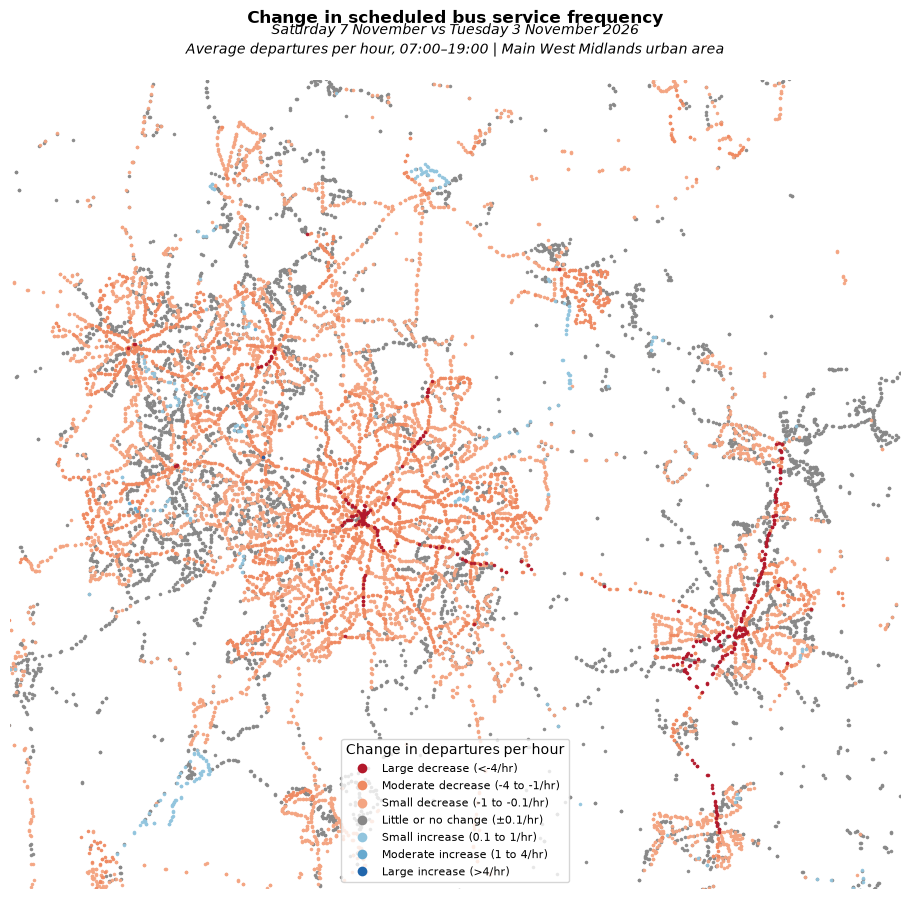

In [24]:
# Map changes in daytime bus frequency: Saturday vs Tuesday

# Attach frequency differences to stop geometries
gdf_change = gdf_stops.merge(
    frequency_comparison[
        ["stop_id", "change_per_hour"]
    ],
    on="stop_id",
    how="left"
)

# Categorise absolute changes in scheduled departures per hour
change_bins = [
    -float("inf"), -4, -1, -0.1,
    0.1, 1, 4, float("inf")
]

change_labels = [
    "Large decrease (<-4/hr)",
    "Moderate decrease (-4 to -1/hr)",
    "Small decrease (-1 to -0.1/hr)",
    "Little or no change (±0.1/hr)",
    "Small increase (0.1 to 1/hr)",
    "Moderate increase (1 to 4/hr)",
    "Large increase (>4/hr)"
]

gdf_change["change_band"] = pd.cut(
    gdf_change["change_per_hour"],
    bins=change_bins,
    labels=change_labels
)

change_colours = {
    "Large decrease (<-4/hr)": "#b2182b",
    "Moderate decrease (-4 to -1/hr)": "#ef8a62",
    "Small decrease (-1 to -0.1/hr)": "#f4a582",
    "Little or no change (±0.1/hr)": "#888888",
    "Small increase (0.1 to 1/hr)": "#92c5de",
    "Moderate increase (1 to 4/hr)": "#67a9cf",
    "Large increase (>4/hr)": "#2166ac"
}

fig, ax = plt.subplots(figsize=(11, 9))

# Plot neutral points first, then changes
plot_order = [
    "Little or no change (±0.1/hr)",
    "Small decrease (-1 to -0.1/hr)",
    "Small increase (0.1 to 1/hr)",
    "Moderate decrease (-4 to -1/hr)",
    "Moderate increase (1 to 4/hr)",
    "Large decrease (<-4/hr)",
    "Large increase (>4/hr)"
]

for band in plot_order:
    subset = gdf_change[
        gdf_change["change_band"] == band
    ]
    if not subset.empty:
        subset.plot(
            ax=ax,
            color=change_colours[band],
            markersize=2.5,
            alpha=0.9
        )

# Match the geographic extent of the main frequency map
map_extent = (-2.25, -1.35, 52.25, 52.75)

extent_gdf = gpd.GeoSeries(
    [box(
        map_extent[0], map_extent[2],
        map_extent[1], map_extent[3]
    )],
    crs="EPSG:4326"
).to_crs(gdf_change.crs)

xmin, ymin, xmax, ymax = extent_gdf.total_bounds
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=change_colours[band],
        markeredgecolor="none",
        markersize=7,
        label=band
    )
    for band in change_labels
]

ax.legend(
    handles=handles,
    title="Change in departures per hour",
    loc="lower center",
    fontsize=8,
    frameon=True
)

ax.text(
    0.5, 1.07,
    "Change in scheduled bus service frequency",
    transform=ax.transAxes,
    ha="center",
    fontsize=12,
    fontweight="bold"
)

ax.text(
    0.5, 1.025,
    "Saturday 7 November vs Tuesday 3 November 2026\n"
    "Average departures per hour, 07:00–19:00 | Main West Midlands urban area",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=10,
    fontstyle="italic",
    linespacing=1.4
)

ax.set_axis_off()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /"wm_weekday_weekend_frequency_change.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

#### Spatial variation in weekday and weekend service provision

The comparison identifies a 17% reduction in scheduled trips between Tuesday and Saturday. Daytime bus departures decrease by 16%, while the number of stops receiving scheduled daytime bus service falls from 29,282 to 27,166 (7%).

The frequency-change map shows that these reductions are not evenly distributed. Decreases are evident along numerous bus corridors, particularly around Birmingham and Coventry, while other locations maintain broadly similar scheduled frequencies. Increases in Saturday service are comparatively limited. These findings indicate that weekend service changes affect both the frequency and geographical coverage of scheduled bus provision.

The map shows absolute changes in average scheduled departures per hour between 07:00 and 19:00. It does not measure passenger demand, service reliability or the accessibility consequences of these changes.

In [25]:
# Date label for the main analysis
day = analysis_date.strftime("%Y_%m_%d")

# 1. Top 50 stops by scheduled trips on the selected date
top50_export = (
    compare.sort_values("daily_trips", ascending=False)
    .head(50)
    [[
        "stop_id",
        "stop_name",
        "daily_trips"
    ]]
    .rename(columns={
        "daily_trips": "scheduled_trips"
    })
)

top50_export.to_csv(
    OUTPUT_DIR / f"wm_top50_stops_{day}.csv",
    index=False
)

# 2. Daytime bus frequency by stop
bus_freq.to_csv(
    OUTPUT_DIR / f"wm_bus_frequency_{day}.csv",
    index=False
)

# 3. Potential bus hubs (8+ routes)
hub_export = (
    stop_profile[stop_profile["n_routes"] >= 8]
    .merge(
        stops[["stop_id", "stop_lat", "stop_lon"]],
        on="stop_id",
        how="left"
    )
    .sort_values("departures_per_hour", ascending=False)
)

hub_export.to_csv(
    OUTPUT_DIR / f"wm_bus_hubs_{day}.csv",
    index=False
)

# 4. Tuesday–Saturday daytime frequency comparison
frequency_comparison.to_csv(
    OUTPUT_DIR / "wm_tuesday_saturday_frequency_comparison.csv",
    index=False
)

# Confirm saved files
print("Saved analysis:\n")

for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print(f"{file.name}: {file.stat().st_size / 1e6:.2f} MB")


Saved analysis:

wm_bus_frequency_2026_11_03.csv: 3.36 MB
wm_bus_hubs_2026_11_03.csv: 0.09 MB
wm_top50_stops_2026_11_03.csv: 0.00 MB
wm_tuesday_saturday_frequency_comparison.csv: 2.07 MB


## Key findings and conclusions

### Key findings

The analysis of archived West Midlands GTFS timetable data identifies substantial variation in scheduled public transport provision across the regional network.

**1. Scheduled service frequency varies considerably between stops and throughout the day.**

Scheduled bus departures are concentrated along frequently served corridors and at major interchange locations. The frequency analysis also reveals differences between morning peak, interpeak, afternoon peak and evening provision, demonstrating that an overall daytime average does not fully describe the availability of services.

**2. Most bus stops are served by relatively few routes.**

Of the 29,282 stops with scheduled daytime bus departures on Tuesday 3 November 2026, approximately 85% are served by three or fewer distinct routes. Only 519 stops (1.8%) are served by eight or more routes, indicating that route diversity is concentrated at a relatively small proportion of locations.

**3. High route diversity does not necessarily indicate frequent all-day service.**

Of the 519 potential bus hubs, 92 have at least 20 scheduled daytime departures per hour, while 427 fall below this threshold.

Further examination of selected stops reveals that some locations with numerous routes have departures concentrated around typical school travel times, rather than distributed throughout the day. This illustrates why route diversity and scheduled frequency should be considered together when assessing service provision.

**4. Saturday service provision is lower than Tuesday provision, but the changes are spatially uneven.**

Comparing Tuesday 3 November with Saturday 7 November 2026:

- Scheduled trips across all transport modes decrease by 17.0%, from 36,410 to 30,206.
- Scheduled daytime bus departure events decrease by 16.0%, from 1,105,103 to 928,756.
- Stops receiving scheduled daytime bus service decrease by 7.2%, from 29,282 to 27,166.

The frequency-change map indicates that reductions are geographically uneven, with substantial decreases along some corridors while other locations retain broadly similar levels of scheduled service.

### Limitations

Several limitations should be considered when interpreting these findings.

- **Scheduled rather than observed services:** GTFS data describes planned timetables. It does not establish whether services operated, arrived punctually or experienced disruption.
- **Geographic coverage:** The archived feed includes services extending beyond the metropolitan West Midlands. Results therefore describe the wider network represented in the dataset, while the static frequency maps focus on the main West Midlands urban area.
- **Frequency measurement:** Average scheduled departures per hour describe stop-level service activity, not passenger waiting times or the frequency of individual routes. They do not account for uneven spacing between departures.
- **Route diversity:** Distinct GTFS route identifiers do not necessarily correspond to distinct destinations or useful interchange opportunities.
- **Hub classification:** The thresholds of eight routes and 20 departures per hour are exploratory analytical choices rather than established definitions of transport hubs. Identified hubs are not verified passenger interchange locations.
- **Temporal coverage:** The main analysis examines one selected date, with a comparison between one Tuesday and one Saturday. These dates cannot establish typical seasonal or long-term service patterns.
- **Accessibility and demand:** The analysis does not incorporate population distribution, passenger demand, journey times or walking access to stops. It therefore cannot determine whether service provision adequately meets local transport needs.

### Conclusion

This analysis demonstrates how GTFS timetable data can be used to examine the spatial and temporal distribution of scheduled public transport provision.

Combining departure frequency, route diversity and geographic analysis provides a more informative picture of the network than any single measure alone. In particular, the findings highlight the distinction between stops offering numerous routes and those providing frequent services throughout the day.

The weekday–weekend comparison further demonstrates that changes in scheduled provision affect both service frequency and the number of stops served, with uneven impacts across the network.

The approach provides a reproducible foundation for further transport network analysis. Future work could incorporate population and accessibility data to investigate how differences in scheduled provision relate to the communities served.